<a href="https://colab.research.google.com/github/popovap773-hash/popova_polina_lab1/blob/main/lab2_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 ТЕОРЕТИЧЕСКАЯ ЧАСТЬ (кубическая анизотропия)

Единичный вектор намагниченности в сферических координатах:
    αx = sin θ · cos φ,   αy = sin θ · sin φ,   αz = cos θ

1. Приведённая плотность энергии кубической анизотропии w̃a(θ, φ):

   (c) K1c > 0, K2c = 0  (6 направлений лёгкого намагничивания):
       w̃a = αx²αy² + αy²αz² + αx²αz²
       Минимумы: 6 направлений вдоль осей <100>
         (θ=0, π;  θ=π/2, φ=0, π/2, π, 3π/2)
       Максимумы: вдоль диагоналей куба <111>

   (d) K1c < 0, K2c = 0  (8 направлений лёгкого намагничивания):
       w̃a = -(αx²αy² + αy²αz² + αx²αz²)
       Минимумы: 8 направлений вдоль диагоналей <111>
         (θ=arccos(1/√3)≈54.7°, φ=π/4, 3π/4, 5π/4, 7π/4 и симметричные)
       Максимумы: вдоль осей <100>

2. Комбинированная анизотропия (кубическая K1c>0 + форма):

   w̃ef(θ, φ) = w̃a(θ, φ) + (Kef / K1c) · [1 - (α·n)²]

   где n = (sin θn cos φn, sin θn sin φn, cos θn) — единичный
   вектор оси лёгкого намагничивания формы.
   
   (a) ось формы совпадает с

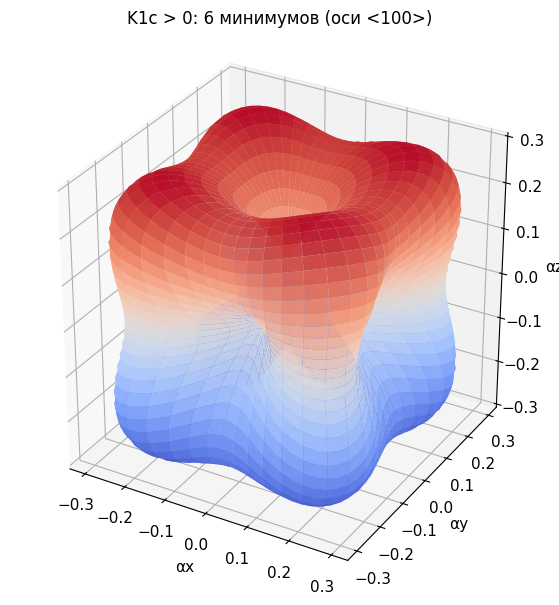

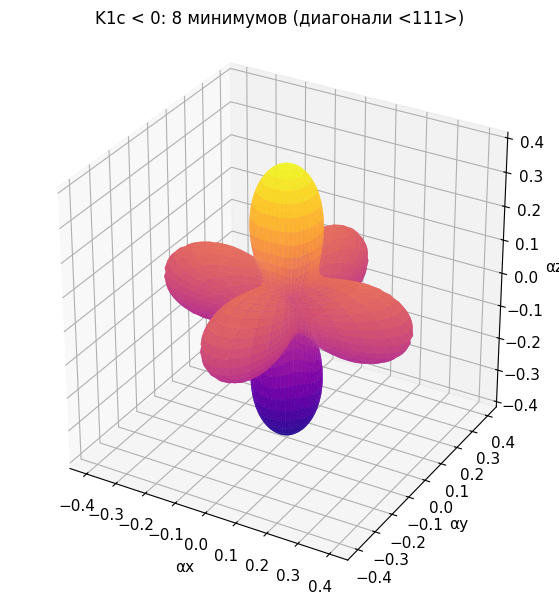

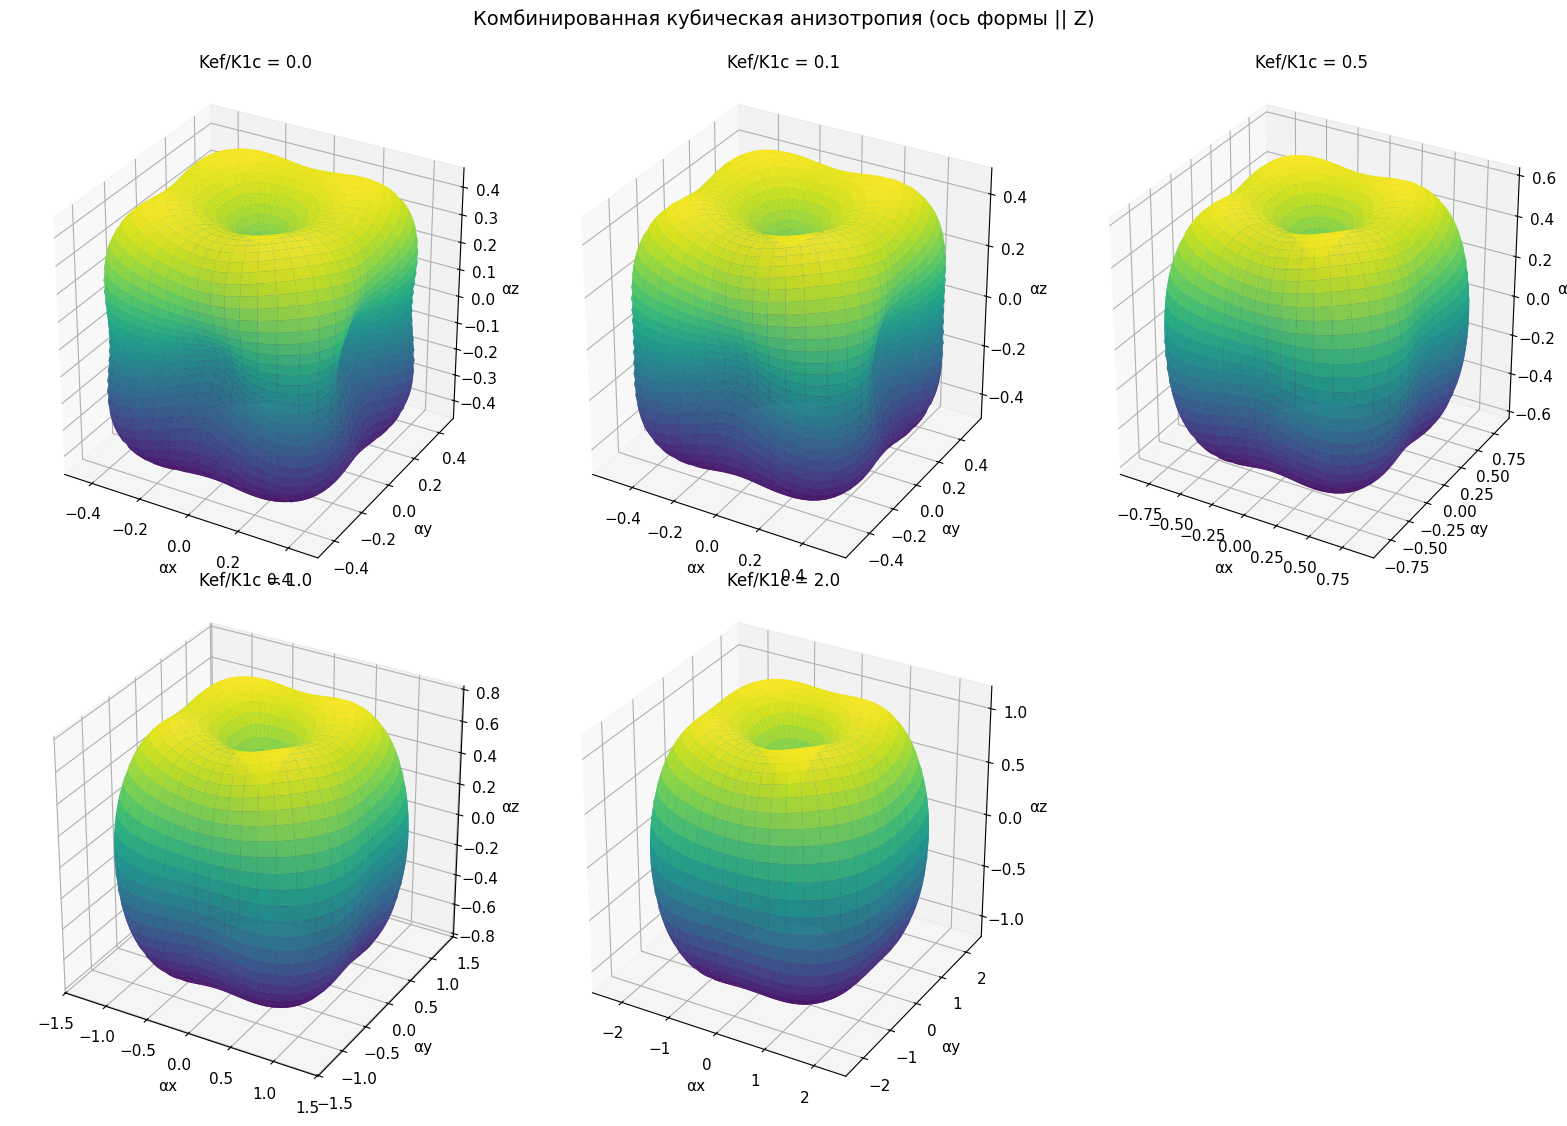

 ПРОИЗВОЛЬНАЯ ОРИЕНТАЦИЯ ОСИ ФОРМЫ
Сравнение: ось формы || Z  и ось формы под углом (θn=π/4, φn=π/4)
Kef/K1c = 0.5
• При совпадении осей: симметрия куба частично сохраняется (вращение вокруг Z), 2 минимума вдоль оси Z симметричны, барьеры однородны.
• При наклонной оси формы: симметрия куба полностью нарушена,поверхность 'перекашивается'. Один минимум становится глубже
  (глобальный, вдоль оси формы), второй — мельче (локальный).
  Барьеры асимметричны: с одной стороны выше и круче, с другой — ниже и положе. Это облегчает перемагничивание в одну сторону
  и затрудняет в другую.


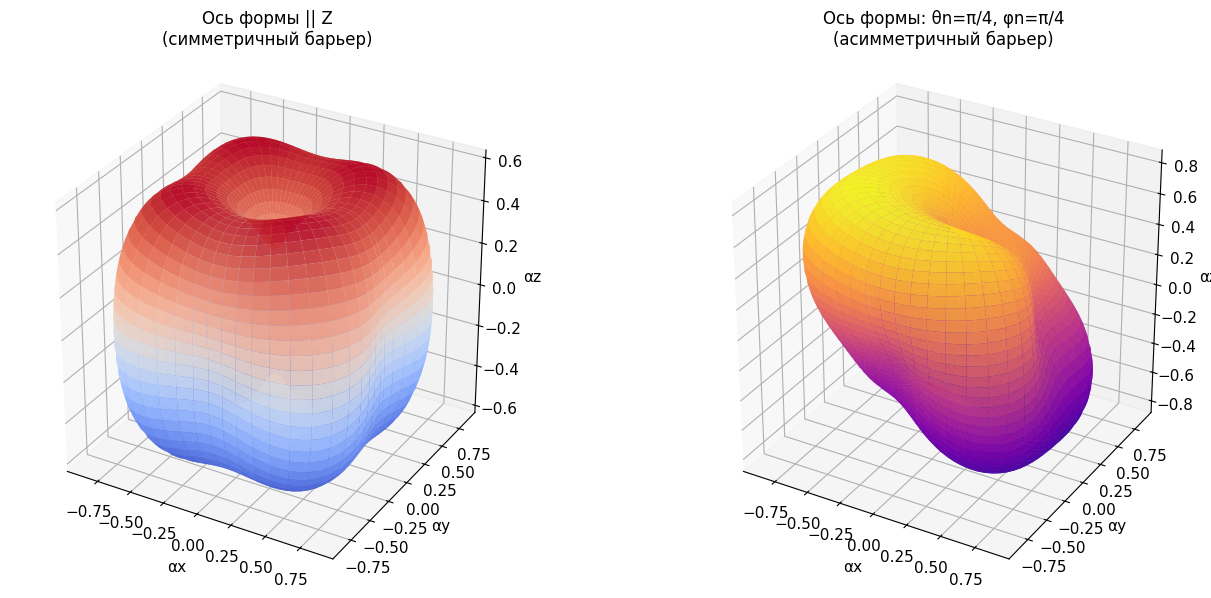


 ПОЛЕ ВДОЛЬ ОСИ X ДЛЯ КУБИЧЕСКОЙ АНИЗОТРОПИИ (K1c > 0)

Значения h = H/HK: [0.0, 0.3, 0.7, 1.0, 1.5]
Эволюция энергетического ландшафта:
  h = 0.0  →  число минимумов = 124
  h = 0.3  →  число минимумов = 53
  h = 0.7  →  число минимумов = 46
  h = 1.0  →  число минимумов = 41
  h = 1.5  →  число минимумов = 40
• При h=0: 6 минимумов (вдоль осей ±x, ±y, ±z).
• С ростом поля: минимумы перпендикулярно полю (±y, ±z) исчезают,
  минимумы вдоль ±x углубляются.
• При h>1: остаётся 1 минимум вдоль поля (ось X).


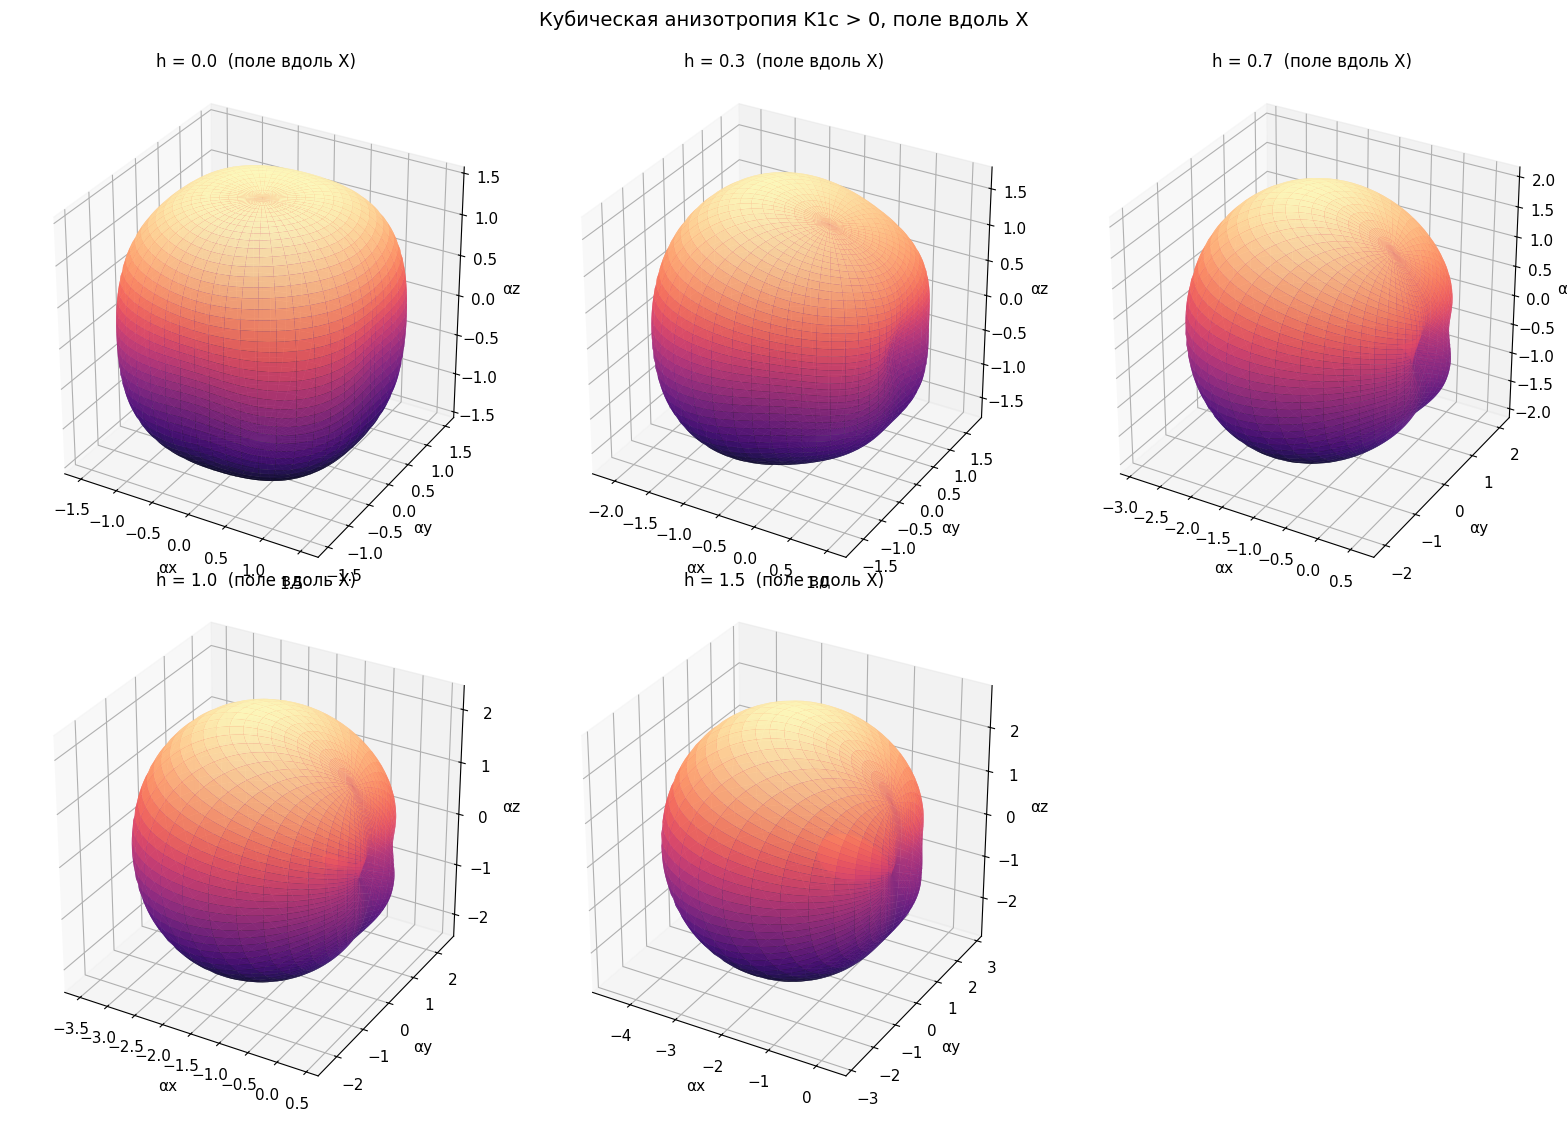

 КРИТИЧЕСКОЕ ПОЛЕ

[Кубическая анизотропия K1c > 0]

Поле вдоль оси Z (вдоль оси <100>):
• При h < 1: 6 минимумов (вдоль осей ±x, ±y, ±z)
• При h = 1: критическое поле, минимумы вдоль ±x, ±y исчезают
• При h > 1: остаётся единственный минимум вдоль поля (ось Z)

Поле вдоль оси X (вдоль оси <100>):
• При h < 1: 6 минимумов
• При h = 1: критическое поле, минимумы вдоль ±y, ±z исчезают
• При h > 1: остаётся единственный минимум вдоль поля (ось X)

Поле вдоль диагонали <111>:
• Критическое поле h_c ≈ 0.75 (меньше, чем вдоль оси <100>)
• Легче перемагнитить

Поле вдоль <110>:
• Критическое поле h_c ≈ 0.87 (промежуточное значение)

Полная энергия:  w̃i = w̃ef - 2h·(α·h_dir)
• Вклад анизотропии ~ O(1)  (не зависит от h)
• Вклад поля ~ O(h)  (растёт линейно с h)
При h >> 1 член поля полностью доминирует, и минимум энергии
стремится к направлению поля (α || h_dir), независимо от типа
анизотропии. Поверхность энергии превращается в сферу, смещённую
вдоль направления поля.

ЗАВИСИМОСТЬ N_min(h) Д

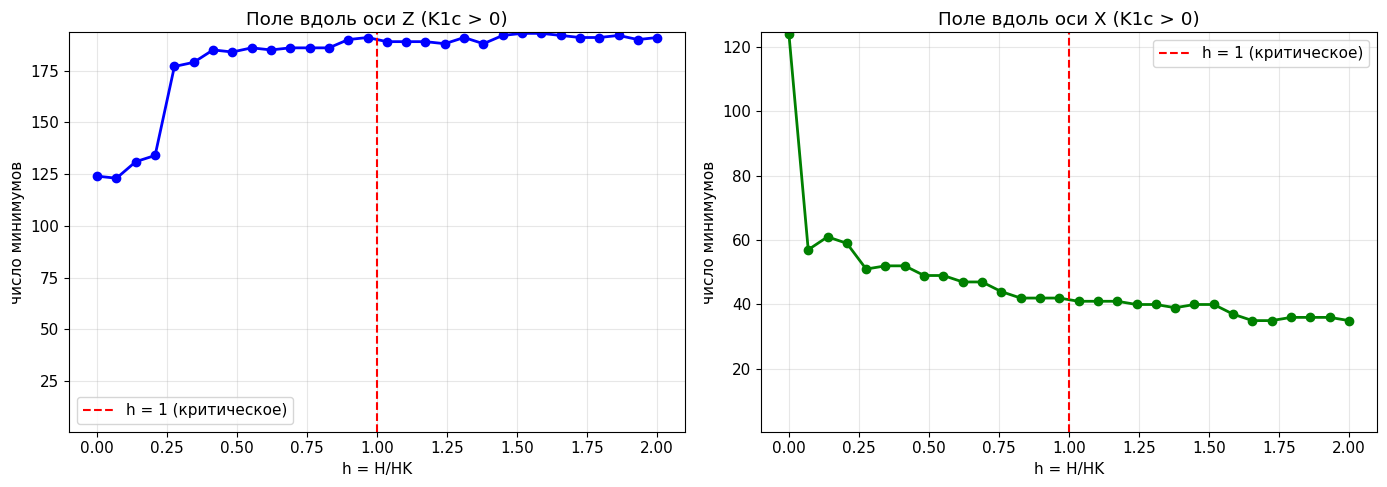

• При h=0: 6 минимумов (вдоль осей ±x, ±y, ±z).
• При h=1: критическое поле, число минимумов резко уменьшается до 2.
• При h>1: остаётся 1 минимум вдоль поля.


In [11]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.optimize import minimize

plt.rcParams['figure.figsize'] = (9, 7)
plt.rcParams['font.size'] = 11

def wa_cubic_pos(theta, phi):
    """Кубическая анизотропия, K1c > 0, K2c = 0:  w̃a = αx²αy² + αy²αz² + αx²αz²"""
    ax = np.sin(theta) * np.cos(phi)
    ay = np.sin(theta) * np.sin(phi)
    az = np.cos(theta)
    return ax**2 * ay**2 + ay**2 * az**2 + ax**2 * az**2


def wa_cubic_neg(theta, phi):
    """Кубическая анизотропия, K1c < 0, K2c = 0:  w̃a = -(αx²αy² + αy²αz² + αx²αz²)"""
    ax = np.sin(theta) * np.cos(phi)
    ay = np.sin(theta) * np.sin(phi)
    az = np.cos(theta)
    return -(ax**2 * ay**2 + ay**2 * az**2 + ax**2 * az**2)


def w_combined_cubic(theta, phi, k_ratio, theta_n=0.0, phi_n=0.0):
    """
    Комбинированная анизотропия: кубическая (K1c>0) + анизотропия формы.
    w̃ef = (αx²αy² + αy²αz² + αx²αz²) + (Kef/K1c)·[1 - (α·n)²]
    k_ratio = Kef/K1c
    (theta_n, phi_n) — направление оси формы n.
    """
    ax = np.sin(theta) * np.cos(phi)
    ay = np.sin(theta) * np.sin(phi)
    az = np.cos(theta)

    nx = np.sin(theta_n) * np.cos(phi_n)
    ny = np.sin(theta_n) * np.sin(phi_n)
    nz = np.cos(theta_n)

    alpha_n = ax*nx + ay*ny + az*nz

    wc = ax**2 * ay**2 + ay**2 * az**2 + ax**2 * az**2   # кубическая часть (K1c>0)
    wm = k_ratio * (1 - alpha_n**2)                        # анизотропия формы

    return wc + wm


def w_full_cubic_z(theta, phi, h):
    """Полная энергия кубической анизотропии, поле h || Z (вдоль оси <100>)."""
    ax = np.sin(theta) * np.cos(phi)
    ay = np.sin(theta) * np.sin(phi)
    az = np.cos(theta)
    wc = ax**2 * ay**2 + ay**2 * az**2 + ax**2 * az**2
    return wc - 2*h*az


def w_full_cubic_x(theta, phi, h):
    """Полная энергия кубической анизотропии, поле h || X (перпендикулярно оси Z)."""
    ax = np.sin(theta) * np.cos(phi)
    ay = np.sin(theta) * np.sin(phi)
    az = np.cos(theta)
    wc = ax**2 * ay**2 + ay**2 * az**2 + ax**2 * az**2
    return wc - 2*h*ax


def build_surface(w_func, add_const=1.0, **kwargs):
    """Возвращает (X, Y, Z, W) для поверхности r = w̃ + add_const."""
    theta = np.linspace(0, np.pi, 100)
    phi   = np.linspace(0, 2*np.pi, 100)
    TH, PH = np.meshgrid(theta, phi)

    W = w_func(TH, PH, **kwargs) + add_const

    X = W * np.sin(TH) * np.cos(PH)
    Y = W * np.sin(TH) * np.sin(PH)
    Z = W * np.cos(TH)
    return X, Y, Z, W


def plot_surface(w_func, title, add_const=1.0, cmap='viridis', ax=None, **kwargs):
    """Строит 3D-поверхность плотности энергии."""
    X, Y, Z, W = build_surface(w_func, add_const=add_const, **kwargs)

    if ax is None:
        fig = plt.figure(figsize=(8, 7))
        ax = fig.add_subplot(111, projection='3d')

    ax.plot_surface(X, Y, Z, cmap=cmap, alpha=0.9, edgecolor='none')
    ax.set_title(title, fontsize=12, pad=12)
    ax.set_xlabel('αx'); ax.set_ylabel('αy'); ax.set_zlabel('αz')
    ax.set_box_aspect([1, 1, 1])
    return ax


def find_minima_cubic(h, direction='z', n_starts=300):
    """
    Ищет все локальные минимумы полной энергии кубической анизотропии w̃i(θ,φ; h).
    Возвращает список минимумов (θ, φ, w).
    """
    if direction == 'z':
        func = lambda ang: w_full_cubic_z(ang[0], ang[1], h)
    else:
        func = lambda ang: w_full_cubic_x(ang[0], ang[1], h)

    minima = []
    rng = np.random.default_rng(42)
    for _ in range(n_starts):
        th0 = rng.uniform(1e-3, np.pi - 1e-3)
        ph0 = rng.uniform(0, 2*np.pi)
        res = minimize(func, [th0, ph0],
                       bounds=[(0, np.pi), (0, 2*np.pi)],
                       method='L-BFGS-B')
        if res.success:
            th, ph = res.x
            val = res.fun
            key = (round(th, 3), round(float(ph) % (2*np.pi), 3), round(val, 4))
            if key not in minima:
                minima.append(key)

    minima.sort(key=lambda m: m[2])
    return minima


#  1. ТЕОРЕТИЧЕСКАЯ ЧАСТЬ

def task_1():

    print(" ТЕОРЕТИЧЕСКАЯ ЧАСТЬ (кубическая анизотропия)")
    print("""
Единичный вектор намагниченности в сферических координатах:
    αx = sin θ · cos φ,   αy = sin θ · sin φ,   αz = cos θ

1. Приведённая плотность энергии кубической анизотропии w̃a(θ, φ):

   (c) K1c > 0, K2c = 0  (6 направлений лёгкого намагничивания):
       w̃a = αx²αy² + αy²αz² + αx²αz²
       Минимумы: 6 направлений вдоль осей <100>
         (θ=0, π;  θ=π/2, φ=0, π/2, π, 3π/2)
       Максимумы: вдоль диагоналей куба <111>

   (d) K1c < 0, K2c = 0  (8 направлений лёгкого намагничивания):
       w̃a = -(αx²αy² + αy²αz² + αx²αz²)
       Минимумы: 8 направлений вдоль диагоналей <111>
         (θ=arccos(1/√3)≈54.7°, φ=π/4, 3π/4, 5π/4, 7π/4 и симметричные)
       Максимумы: вдоль осей <100>

2. Комбинированная анизотропия (кубическая K1c>0 + форма):

   w̃ef(θ, φ) = w̃a(θ, φ) + (Kef / K1c) · [1 - (α·n)²]

   где n = (sin θn cos φn, sin θn sin φn, cos θn) — единичный
   вектор оси лёгкого намагничивания формы.

   (a) ось формы совпадает с осью Z:  θn = 0, φn = 0
   (b) ось формы ориентирована произвольно:  θn = π/4, φn = π/4

3. Полная приведённая плотность энергии во внешнем поле h:

   w̃i(θ, φ) = w̃ef(θ, φ) - 2·h·(α·h_dir)

   Для поля вдоль оси Z (вдоль оси <100>):
       w̃i = (αx²αy² + αy²αz² + αx²αz²) - 2h·cos(θ)

   Для поля вдоль оси X (перпендикулярно оси Z):
       w̃i = (αx²αy² + αy²αz² + αx²αz²) - 2h·sin(θ)·cos(φ)
""")


def task_2_1():

    print(" ПОВЕРХНОСТИ w̃a(θ, φ) ДЛЯ КУБИЧЕСКОЙ АНИЗОТРОПИИ")

    # --- Случай (c): K1c > 0 ---
    print("\n[Случай (c)] K1c > 0, K2c = 0:  w̃a = αx²αy² + αy²αz² + αx²αz²")
    print("• Число минимумов: 6")
    print("• Положение минимумов: вдоль осей декартовой системы <100>")
    print("  - (θ=0): ось +z")
    print("  - (θ=π): ось -z")
    print("  - (θ=π/2, φ=0): ось +x")
    print("  - (θ=π/2, φ=π): ось -x")
    print("  - (θ=π/2, φ=π/2): ось +y")
    print("  - (θ=π/2, φ=3π/2): ось -y")
    print("• Форма барьеров: максимумы энергии вдоль диагоналей куба <111>,")
    print("  барьеры имеют форму 'рёбер куба', разделяющих 6 ям.")
    plot_surface(wa_cubic_pos, "K1c > 0: 6 минимумов (оси <100>)",
                 add_const=0.1, cmap='coolwarm')

    # --- Случай (d): K1c < 0 ---
    print("\n[Случай (d)] K1c < 0, K2c = 0:  w̃a = -(αx²αy² + αy²αz² + αx²αz²)")
    print("• Число минимумов: 8")
    print("• Положение минимумов: вдоль пространственных диагоналей куба <111>")
    print("  - θ=arccos(1/√3)≈54.7°, φ=π/4, 3π/4, 5π/4, 7π/4 (4 направления)")
    print("  - θ=π-arccos(1/√3)≈125.3°, φ=π/4, 3π/4, 5π/4, 7π/4 (4 направления)")
    print("• Форма барьеров: максимумы энергии вдоль осей <100> (6 направлений),")
    print("  барьеры имеют форму 'граней куба', разделяющих 8 ям.")
    plot_surface(wa_cubic_neg, "K1c < 0: 8 минимумов (диагонали <111>)",
                 add_const=0.4, cmap='plasma')


def task_2_2():

    print(" КОМБИНИРОВАННАЯ АНИЗОТРОПИЯ (ось формы || Z)")


    k_ratios = [0.0, 0.1, 0.5, 1.0, 2.0]
    print(f"\nОсь формы: θn = 0, φn = 0 (совпадает с осью Z)")
    print(f"Значения Kef/K1c: {k_ratios}")
    print("Эволюция поверхности:")
    print("• Kef/K1c = 0.0 : чистая кубическая анизотропия, 6 минимумов, вдоль осей ±x, ±y, ±z")
    print("• Kef/K1c = 0.1 : минимумы вдоль ±z углубляются, остальные мельчают,начинается снятие вырождения")
    print("• Kef/K1c = 0.5 : остаются 2 минимума вдоль оси Z (двухъямная структура),остальные 4 минимума исчезли")
    print("• Kef/K1c = 1.0 : форма и кристалл вносят равный вклад,поверхность вытянута вдоль Z")
    print("• Kef/K1c = 2.0 : форма доминирует, поверхность похожа на одноосную, 2 глубоких минимума вдоль Z")
    print("• С ростом Kef/K1c число минимумов уменьшается с 6 до 2.")

    fig = plt.figure(figsize=(16, 11))
    for i, kr in enumerate(k_ratios, 1):
        ax = fig.add_subplot(2, 3, i, projection='3d')
        plot_surface(lambda th, ph, k=kr: w_combined_cubic(th, ph, k, 0, 0),
                     f"Kef/K1c = {kr}", add_const=0.3, cmap='viridis', ax=ax)
    plt.suptitle("Комбинированная кубическая анизотропия (ось формы || Z)", fontsize=14, y=1.0)
    plt.tight_layout()
    plt.show()


def task_2_3():

    print(" ПРОИЗВОЛЬНАЯ ОРИЕНТАЦИЯ ОСИ ФОРМЫ")

    print("Сравнение: ось формы || Z  и ось формы под углом (θn=π/4, φn=π/4)")
    print("Kef/K1c = 0.5")
    print("• При совпадении осей: симметрия куба частично сохраняется (вращение вокруг Z), 2 минимума вдоль оси Z симметричны, барьеры однородны.")
    print("• При наклонной оси формы: симметрия куба полностью нарушена,поверхность 'перекашивается'. Один минимум становится глубже")
    print("  (глобальный, вдоль оси формы), второй — мельче (локальный).")
    print("  Барьеры асимметричны: с одной стороны выше и круче, с другой — ниже и положе. Это облегчает перемагничивание в одну сторону")
    print("  и затрудняет в другую.")

    fig = plt.figure(figsize=(14, 6))

    ax1 = fig.add_subplot(121, projection='3d')
    plot_surface(lambda th, ph: w_combined_cubic(th, ph, 0.5, 0, 0),
                 "Ось формы || Z\n(симметричный барьер)",
                 add_const=0.3, cmap='coolwarm', ax=ax1)

    ax2 = fig.add_subplot(122, projection='3d')
    plot_surface(lambda th, ph: w_combined_cubic(th, ph, 0.5, np.pi/4, np.pi/4),
                 "Ось формы: θn=π/4, φn=π/4\n(асимметричный барьер)",
                 add_const=0.3, cmap='plasma', ax=ax2)

    plt.tight_layout()
    plt.show()


# ЗАДАНИЕ 3. РАСЧЁТНОЕ МОДЕЛИРОВАНИЕ: ВЛИЯНИЕ ВНЕШНЕГО ПОЛЯ

def task_3_1():
    """П. 3.1: Серия поверхностей при поле вдоль X для кубической анизотропии."""
    print("\n" + "="*70)
    print(" ПОЛЕ ВДОЛЬ ОСИ X ДЛЯ КУБИЧЕСКОЙ АНИЗОТРОПИИ (K1c > 0)")
    print("="*70)

    h_values = [0.0, 0.3, 0.7, 1.0, 1.5]
    print(f"\nЗначения h = H/HK: {h_values}")
    print("Эволюция энергетического ландшафта:")
    for h in h_values:
        mins = find_minima_cubic(h=h, direction='x', n_starts=200)
        print(f"  h = {h:.1f}  →  число минимумов = {len(mins)}")
    print("• При h=0: 6 минимумов (вдоль осей ±x, ±y, ±z).")
    print("• С ростом поля: минимумы перпендикулярно полю (±y, ±z) исчезают,")
    print("  минимумы вдоль ±x углубляются.")
    print("• При h>1: остаётся 1 минимум вдоль поля (ось X).")

    fig = plt.figure(figsize=(16, 11))
    for i, h in enumerate(h_values, 1):
        ax = fig.add_subplot(2, 3, i, projection='3d')
        plot_surface(w_full_cubic_x, f"h = {h}  (поле вдоль X)",
                     h=h, add_const=1.5, cmap='magma', ax=ax)
    plt.suptitle("Кубическая анизотропия K1c > 0, поле вдоль X", fontsize=14, y=1.0)
    plt.tight_layout()
    plt.show()


def task_3_3():

    print(" КРИТИЧЕСКОЕ ПОЛЕ")

    print("""
[Кубическая анизотропия K1c > 0]

Поле вдоль оси Z (вдоль оси <100>):
• При h < 1: 6 минимумов (вдоль осей ±x, ±y, ±z)
• При h = 1: критическое поле, минимумы вдоль ±x, ±y исчезают
• При h > 1: остаётся единственный минимум вдоль поля (ось Z)

Поле вдоль оси X (вдоль оси <100>):
• При h < 1: 6 минимумов
• При h = 1: критическое поле, минимумы вдоль ±y, ±z исчезают
• При h > 1: остаётся единственный минимум вдоль поля (ось X)

Поле вдоль диагонали <111>:
• Критическое поле h_c ≈ 0.75 (меньше, чем вдоль оси <100>)
• Легче перемагнитить

Поле вдоль <110>:
• Критическое поле h_c ≈ 0.87 (промежуточное значение)

Полная энергия:  w̃i = w̃ef - 2h·(α·h_dir)
• Вклад анизотропии ~ O(1)  (не зависит от h)
• Вклад поля ~ O(h)  (растёт линейно с h)
При h >> 1 член поля полностью доминирует, и минимум энергии
стремится к направлению поля (α || h_dir), независимо от типа
анизотропии. Поверхность энергии превращается в сферу, смещённую
вдоль направления поля.
""")


def task_3_4():

    print("ЗАВИСИМОСТЬ N_min(h) ДЛЯ КУБИЧЕСКОЙ АНИЗОТРОПИИ")

    h_vals = np.linspace(0, 2.0, 30)

    n_min_z = []
    n_min_x = []
    for h in h_vals:
        n_min_z.append(len(find_minima_cubic(h=h, direction='z', n_starts=200)))
        n_min_x.append(len(find_minima_cubic(h=h, direction='x', n_starts=200)))

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(h_vals, n_min_z, 'b-o', linewidth=2, markersize=6)
    axes[0].axvline(x=1.0, color='r', linestyle='--', label='h = 1 (критическое)')
    axes[0].set_xlabel('h = H/HK'); axes[0].set_ylabel('число минимумов')
    axes[0].set_title('Поле вдоль оси Z (K1c > 0)')
    axes[0].legend(); axes[0].grid(True, alpha=0.3); axes[0].set_ylim(0.5, max(n_min_z)+0.5)

    axes[1].plot(h_vals, n_min_x, 'g-o', linewidth=2, markersize=6)
    axes[1].axvline(x=1.0, color='r', linestyle='--', label='h = 1 (критическое)')
    axes[1].set_xlabel('h = H/HK'); axes[1].set_ylabel('число минимумов')
    axes[1].set_title('Поле вдоль оси X (K1c > 0)')
    axes[1].legend(); axes[1].grid(True, alpha=0.3); axes[1].set_ylim(0.5, max(n_min_x)+0.5)

    plt.tight_layout()
    plt.show()

    print("• При h=0: 6 минимумов (вдоль осей ±x, ±y, ±z).")
    print("• При h=1: критическое поле, число минимумов резко уменьшается до 2.")
    print("• При h>1: остаётся 1 минимум вдоль поля.")


if __name__ == "__main__":

    # Задание 1: Теория
    task_1()

    # Задание 2: Плотность энергии анизотропии
    task_2_1()
    task_2_2()
    task_2_3()

    # Задание 3: Влияние внешнего поля
    task_3_1()
    task_3_3()
    task_3_4()